# 🛋️ Báo Cáo Trực Quan Hóa Dữ Liệu Nội Thất (2023 - 2025)
## 📌 Thiết Kế Trực Quan Từ Tổng Quan Đến Chi Tiết (Tối Giản, Dễ Hiểu Nhất)

**Nguyên tắc thiết kế trực quan:**
- **Đi từ vĩ mô đến vi mô:** Bắt đầu từ chỉ số tổng quan (KPIs), xu hướng dòng tiền theo thời gian, đến so sánh cơ cấu mặt hàng và chi tiết chất lượng/rủi ro.
- **Biểu đồ cơ bản, tối ưu nhận thức:** Sử dụng các loại biểu đồ quen thuộc nhất (Cột, Đường, Tròn/Donut, Hộp) giúp người xem nắm bắt thông tin ngay trong 3-5 giây.
- **Ghi nhãn trực tiếp (Direct Data Labels):** Hiển thị rõ số liệu và đơn vị (Tỷ VNĐ, Chiếc, %) ngay trên đồ thị, hạn chế tối đa việc phải tra cứu mắt qua trục tọa độ.

---
### 🧭 Bản Đồ Luồng Báo Cáo (Overview to Detail):
1. **Tầng 1: Tổng quan vĩ mô & Cơ cấu (Executive Overview)**
   - Biểu đồ 1: Tỷ lệ phân bổ Nguồn gốc hàng hóa (Nội địa vs Nhập khẩu).
   - Biểu đồ 2: Cơ cấu tình trạng chất lượng khi nhập kho (Mới, Sửa chữa, Hư hỏng).
2. **Tầng 2: Xu hướng dòng tiền theo thời gian (Trend View)**
   - Biểu đồ 3: Diễn biến giá trị nhập hàng theo từng tháng (2023 - 2025).
3. **Tầng 3: Phân tích danh mục sản phẩm (Category Comparison)**
   - Biểu đồ 4: Bảng xếp hạng Tổng giá trị vốn nhập theo dòng sản phẩm (Cột ngang).
   - Biểu đồ 5: So sánh Nguồn gốc Nội địa vs Nhập khẩu trên từng loại sản phẩm.
4. **Tầng 4: Chi tiết rủi ro chất lượng & Phân bố giá (Deep-dive)**
   - Biểu đồ 6: Tỷ lệ hàng đạt chuẩn và hàng lỗi theo từng mặt hàng (100% Stacked Bar).
   - Biểu đồ 7: Phân bố đơn giá nhập kho của từng loại nội thất (Box Plot).


In [1]:
# 1. Khai báo thư viện và cấu hình hiển thị chuẩn tiếng Việt
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập phong cách hiển thị sạch sẽ, tối giản
sns.set_theme(style="whitegrid", font="Liberation Sans")
plt.rcParams['font.sans-serif'] = ['Liberation Sans', 'DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

IMG_DIR = "images_noi_that"
os.makedirs(IMG_DIR, exist_ok=True)

print("✅ Đã sẵn sàng môi trường trực quan hóa!")


✅ Đã sẵn sàng môi trường trực quan hóa!


In [2]:
# 2. Đọc và tiền xử lý dữ liệu nội thất
data_path = os.path.join("data", "du_lieu_noi_that.csv")
df = pd.read_csv(data_path)

# Chuẩn hóa cột ngày nhập
df['Ngày Nhập'] = pd.to_datetime(df['Ngày Nhập'], format='%d/%m/%Y')
df['Năm'] = df['Ngày Nhập'].dt.year
df['Năm_Tháng'] = df['Ngày Nhập'].dt.to_period('M')

# Tính thành tiền (Giá trị đơn hàng)
df['Thành Tiền (VNĐ)'] = df['Số Lượng'] * df['Giá Nhập (VNĐ)']
df['Thành Tiền (Tỷ VNĐ)'] = df['Thành Tiền (VNĐ)'] / 1_000_000_000
df['Giá Nhập (Triệu VNĐ)'] = df['Giá Nhập (VNĐ)'] / 1_000_000

# Thống kê nhanh chỉ số KPI tổng
tong_don = len(df)
tong_sl = df['Số Lượng'].sum()
tong_von = df['Thành Tiền (VNĐ)'].sum() / 1e9
ty_le_moi = (df[df['Trạng Thái'] == 'Mới']['Số Lượng'].sum() / tong_sl) * 100

print(f"📌 [KPI TỔNG QUAN 2023 - 2025]:")
print(f" - Tổng số lượt nhập hàng: {tong_don:,} lô")
print(f" - Tổng số lượng sản phẩm nhập: {tong_sl:,} chiếc")
print(f" - Tổng vốn nhập kho: {tong_von:,.2f} Tỷ VNĐ")
print(f" - Tỷ lệ sản phẩm Mới (Đạt chuẩn): {ty_le_moi:.1f}%")
df.head(5)


📌 [KPI TỔNG QUAN 2023 - 2025]:
 - Tổng số lượt nhập hàng: 10,000 lô
 - Tổng số lượng sản phẩm nhập: 252,610 chiếc
 - Tổng vốn nhập kho: 1,437.01 Tỷ VNĐ
 - Tỷ lệ sản phẩm Mới (Đạt chuẩn): 69.9%


,ID,Tên Sản Phẩm,Trạng Thái,Số Lượng,Giá Nhập (VNĐ),Ngày Nhập,Nguồn Gốc,Năm,Năm_Tháng,Thành Tiền (VNĐ),Thành Tiền (Tỷ VNĐ),Giá Nhập (Triệu VNĐ)
0,SP00001,Tủ quần áo,Mới,23,6683254,2023-03-15,Nội địa,2023,2023-03,153714842,0.153715,6.683254
1,SP00002,Giường,Hư hỏng,50,14558280,2023-08-08,Nội địa,2023,2023-08,727914000,0.727914,14.558280
2,SP00003,Giường,Mới,47,11739936,2023-08-24,Nhập khẩu,2023,2023-08,551776992,0.551777,11.739936
3,SP00004,Giường,Sửa chữa,34,11214177,2025-11-28,Nhập khẩu,2025,2025-11,381282018,0.381282,11.214177
4,SP00005,Bàn ăn,Sửa chữa,50,5971872,2025-05-11,Nội địa,2025,2025-05,298593600,0.298594,5.971872


---
### 📊 Biểu Đồ 1: Tỷ Trọng Nguồn Gốc Hàng Hóa (Nội Địa vs Nhập Khẩu)
- **Dạng biểu đồ:** Biểu đồ Donut tối giản.
- **Mục đích:** Người xem thấy ngay quy mô nguồn cung hàng hóa của doanh nghiệp.


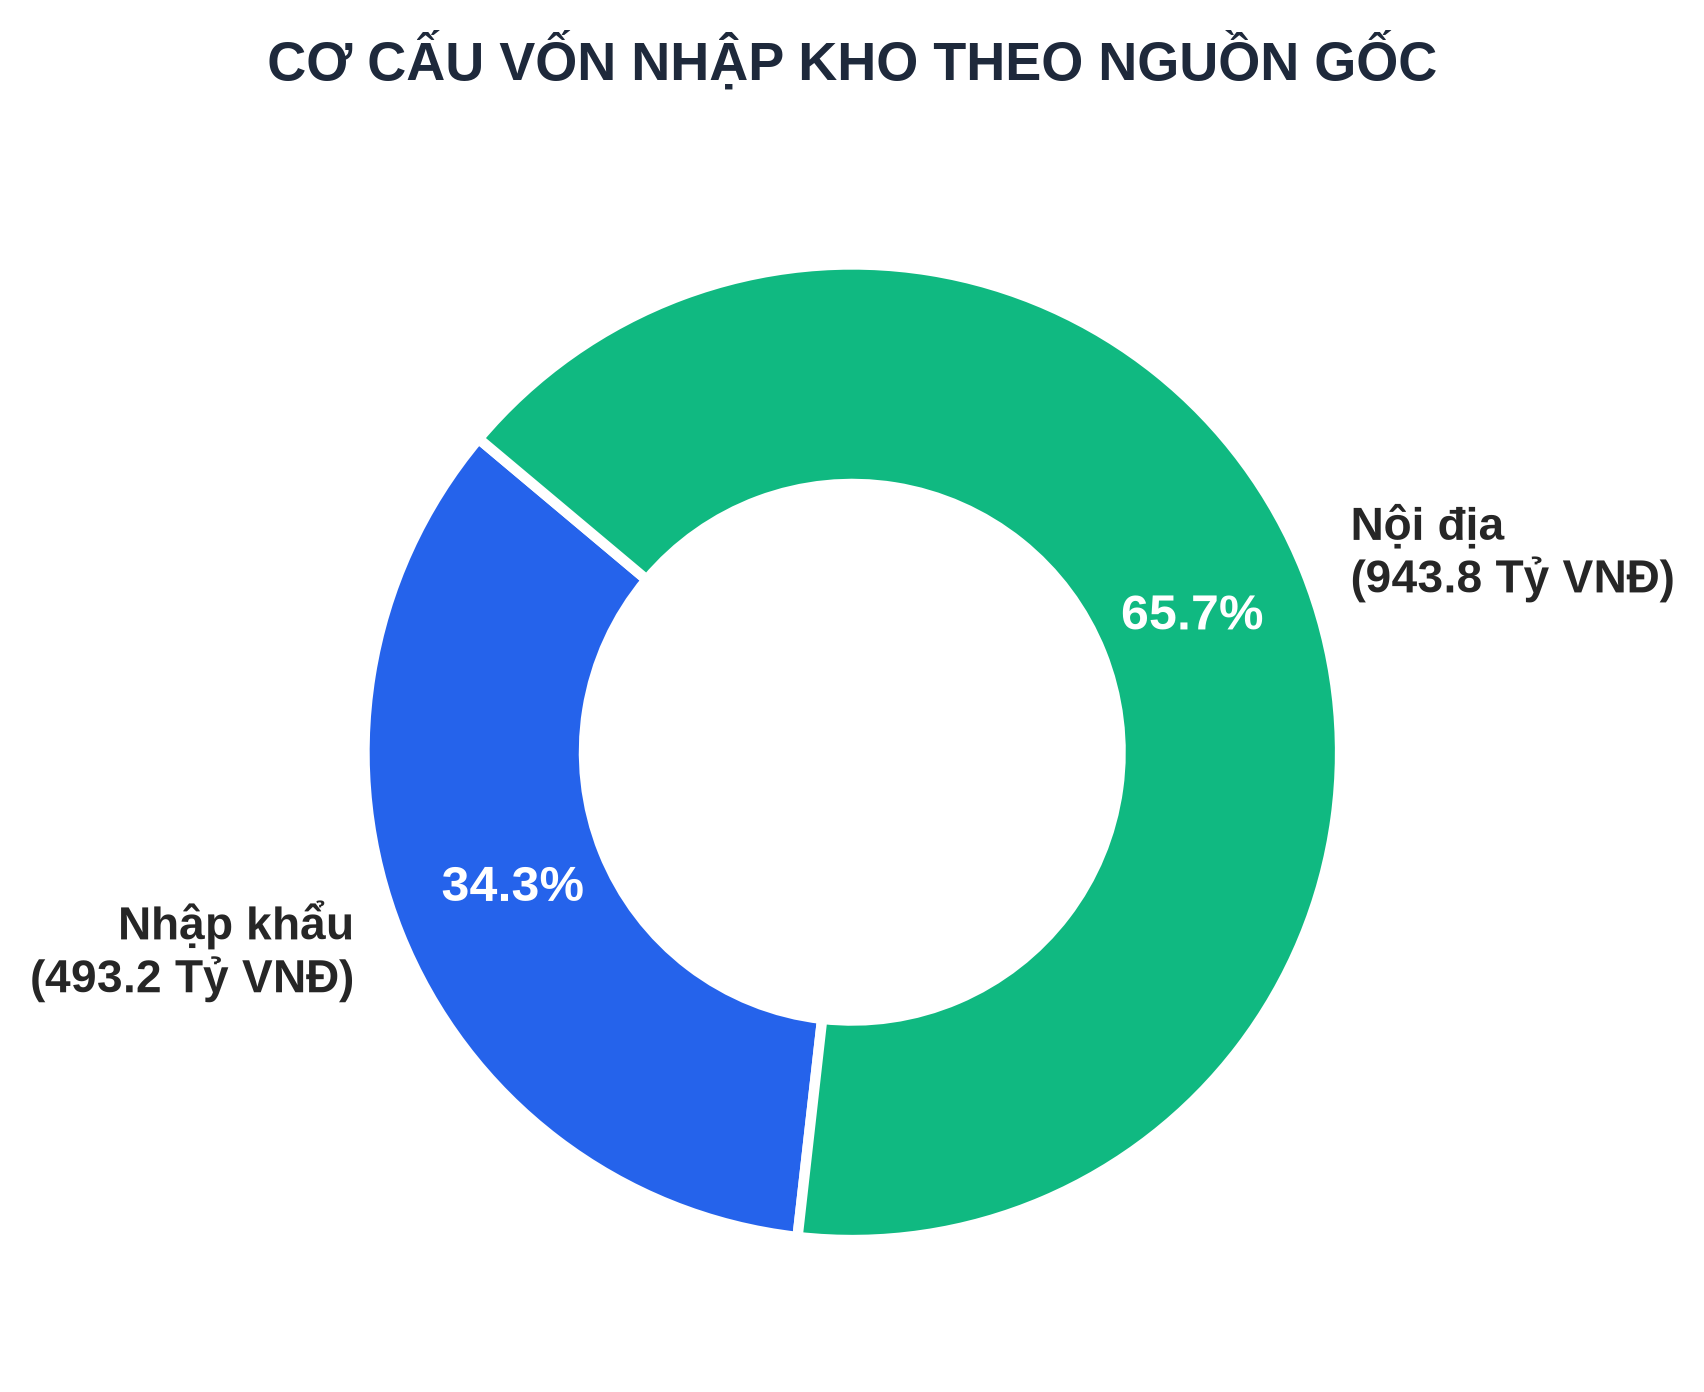

In [3]:
# Biểu đồ 1: Cơ cấu Nguồn Gốc Hàng Hóa
nguon_goc_stats = df.groupby('Nguồn Gốc')['Thành Tiền (VNĐ)'].sum()
nguon_goc_labels = [f"{idx}\n({val/1e9:,.1f} Tỷ VNĐ)" for idx, val in zip(nguon_goc_stats.index, nguon_goc_stats.values)]
colors_nguon_goc = ['#2563EB', '#10B981'] # Xanh dương hiện đại, Xanh ngọc

fig, ax = plt.subplots(figsize=(6.5, 4.8), dpi=300)
wedges, texts, autotexts = ax.pie(
    nguon_goc_stats, 
    labels=nguon_goc_labels, 
    autopct='%1.1f%%',
    startangle=140, 
    colors=colors_nguon_goc,
    pctdistance=0.75,
    textprops={'fontsize': 11, 'fontweight': 'bold'},
    wedgeprops={'width': 0.45, 'edgecolor': 'white', 'linewidth': 2.5}
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(12)

ax.set_title("CƠ CẤU VỐN NHẬP KHO THEO NGUỒN GỐC", fontsize=13, fontweight='bold', pad=15, color='#1E293B')
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "01_co_cau_nguon_goc.png"), bbox_inches='tight')
plt.show()


---
### 📊 Biểu Đồ 2: Tỷ Lệ Tình Trạng Chất Lượng Ban Đầu Khi Nhập Kho
- **Dạng biểu đồ:** Biểu đồ Donut với màu cảnh báo trực quan.
- **Mục đích:** Đo lường tỷ lệ hàng đạt chuẩn (Mới) so với hàng lỗi cần xử lý (Sửa chữa / Hư hỏng).


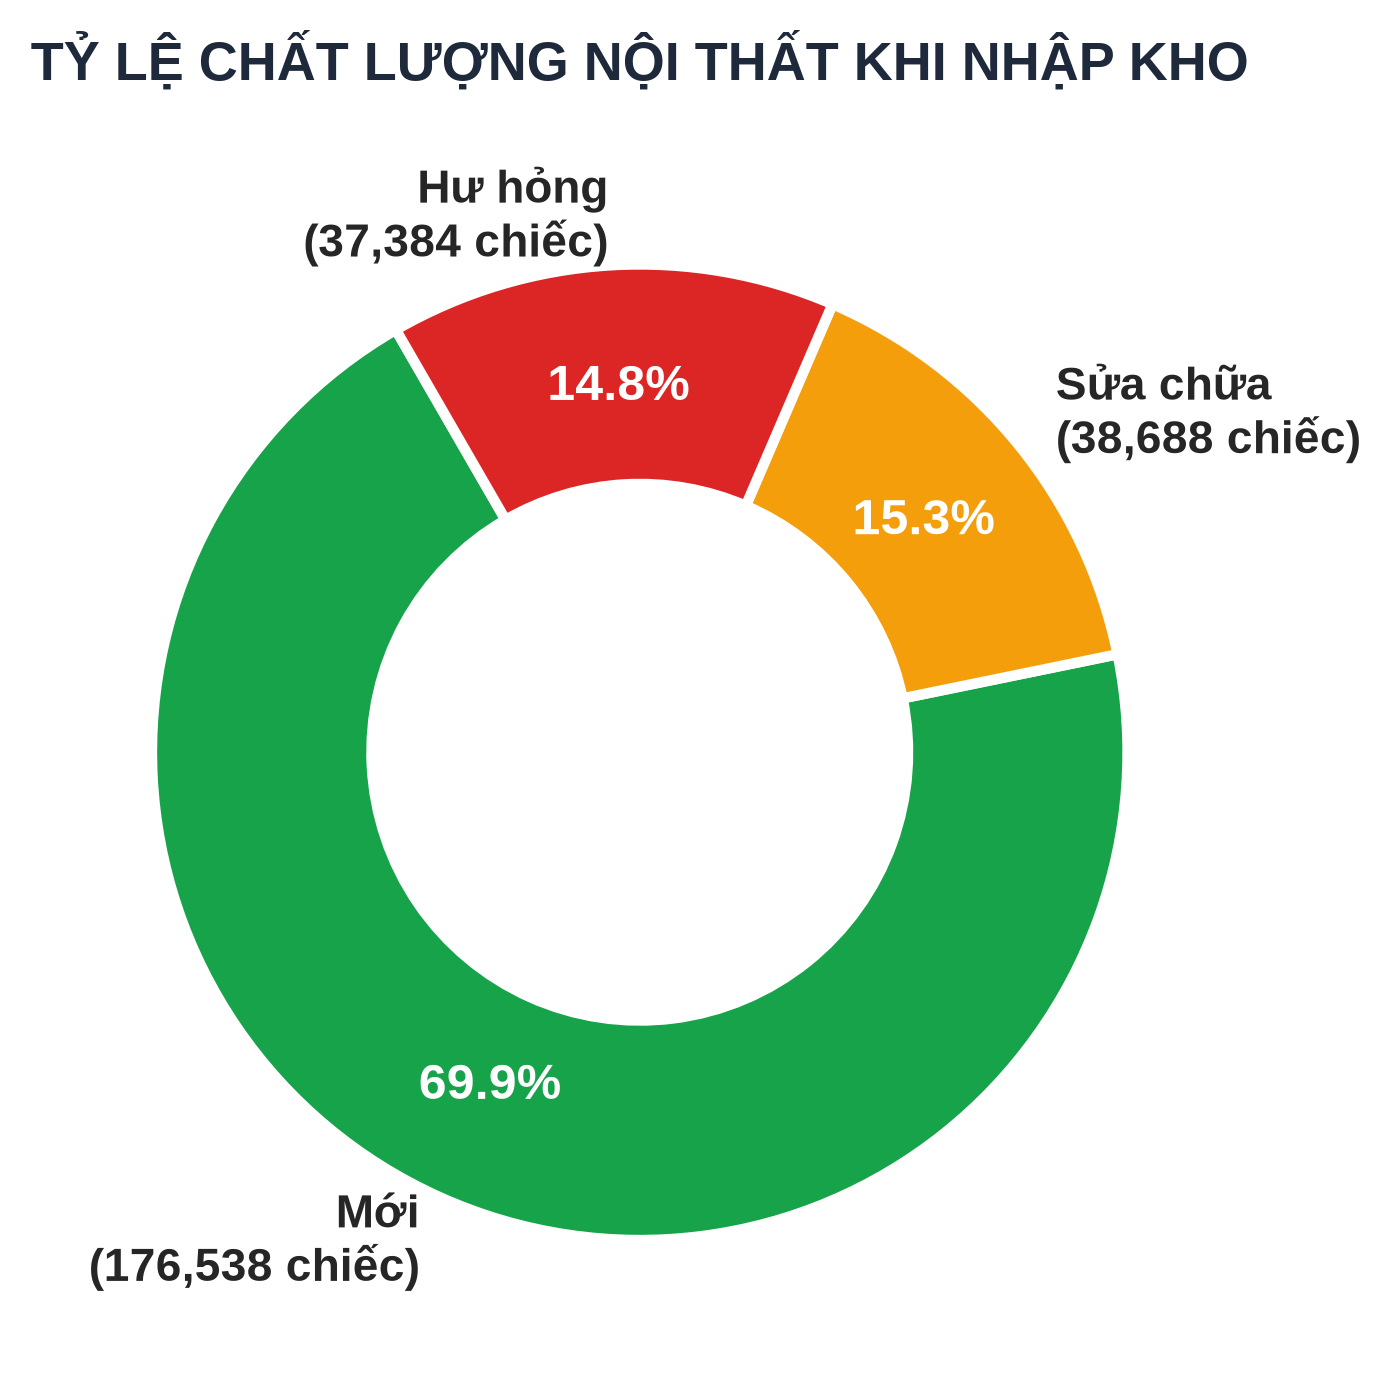

In [4]:
# Biểu đồ 2: Cơ cấu Trạng Thái Chất Lượng
trang_thai_order = ['Mới', 'Sửa chữa', 'Hư hỏng']
trang_thai_stats = df.groupby('Trạng Thái')['Số Lượng'].sum().reindex(trang_thai_order)
colors_trang_thai = ['#16A34A', '#F59E0B', '#DC2626'] # Xanh lá (Mới), Cam (Sửa chữa), Đỏ (Hư hỏng)
labels_tt = [f"{k}\n({v:,} chiếc)" for k, v in zip(trang_thai_stats.index, trang_thai_stats.values)]

fig, ax = plt.subplots(figsize=(6.5, 4.8), dpi=300)
wedges, texts, autotexts = ax.pie(
    trang_thai_stats, 
    labels=labels_tt, 
    autopct='%1.1f%%',
    startangle=120, 
    colors=colors_trang_thai,
    pctdistance=0.75,
    textprops={'fontsize': 11, 'fontweight': 'bold'},
    wedgeprops={'width': 0.45, 'edgecolor': 'white', 'linewidth': 2.5}
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontsize(12)

ax.set_title("TỶ LỆ CHẤT LƯỢNG NỘI THẤT KHI NHẬP KHO", fontsize=13, fontweight='bold', pad=15, color='#1E293B')
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "02_co_cau_trang_thai.png"), bbox_inches='tight')
plt.show()


---
### 📈 Biểu Đồ 3: Xu Hướng Vốn Nhập Kho Theo Từng Tháng (2023 - 2025)
- **Dạng biểu đồ:** Biểu đồ đường (`sns.lineplot`) kèm vùng tô sáng và đường trung bình.
- **Mục đích:** Theo dõi chu kỳ biến động tài chính, phát hiện các giai đoạn giải ngân nhập hàng đột biến.


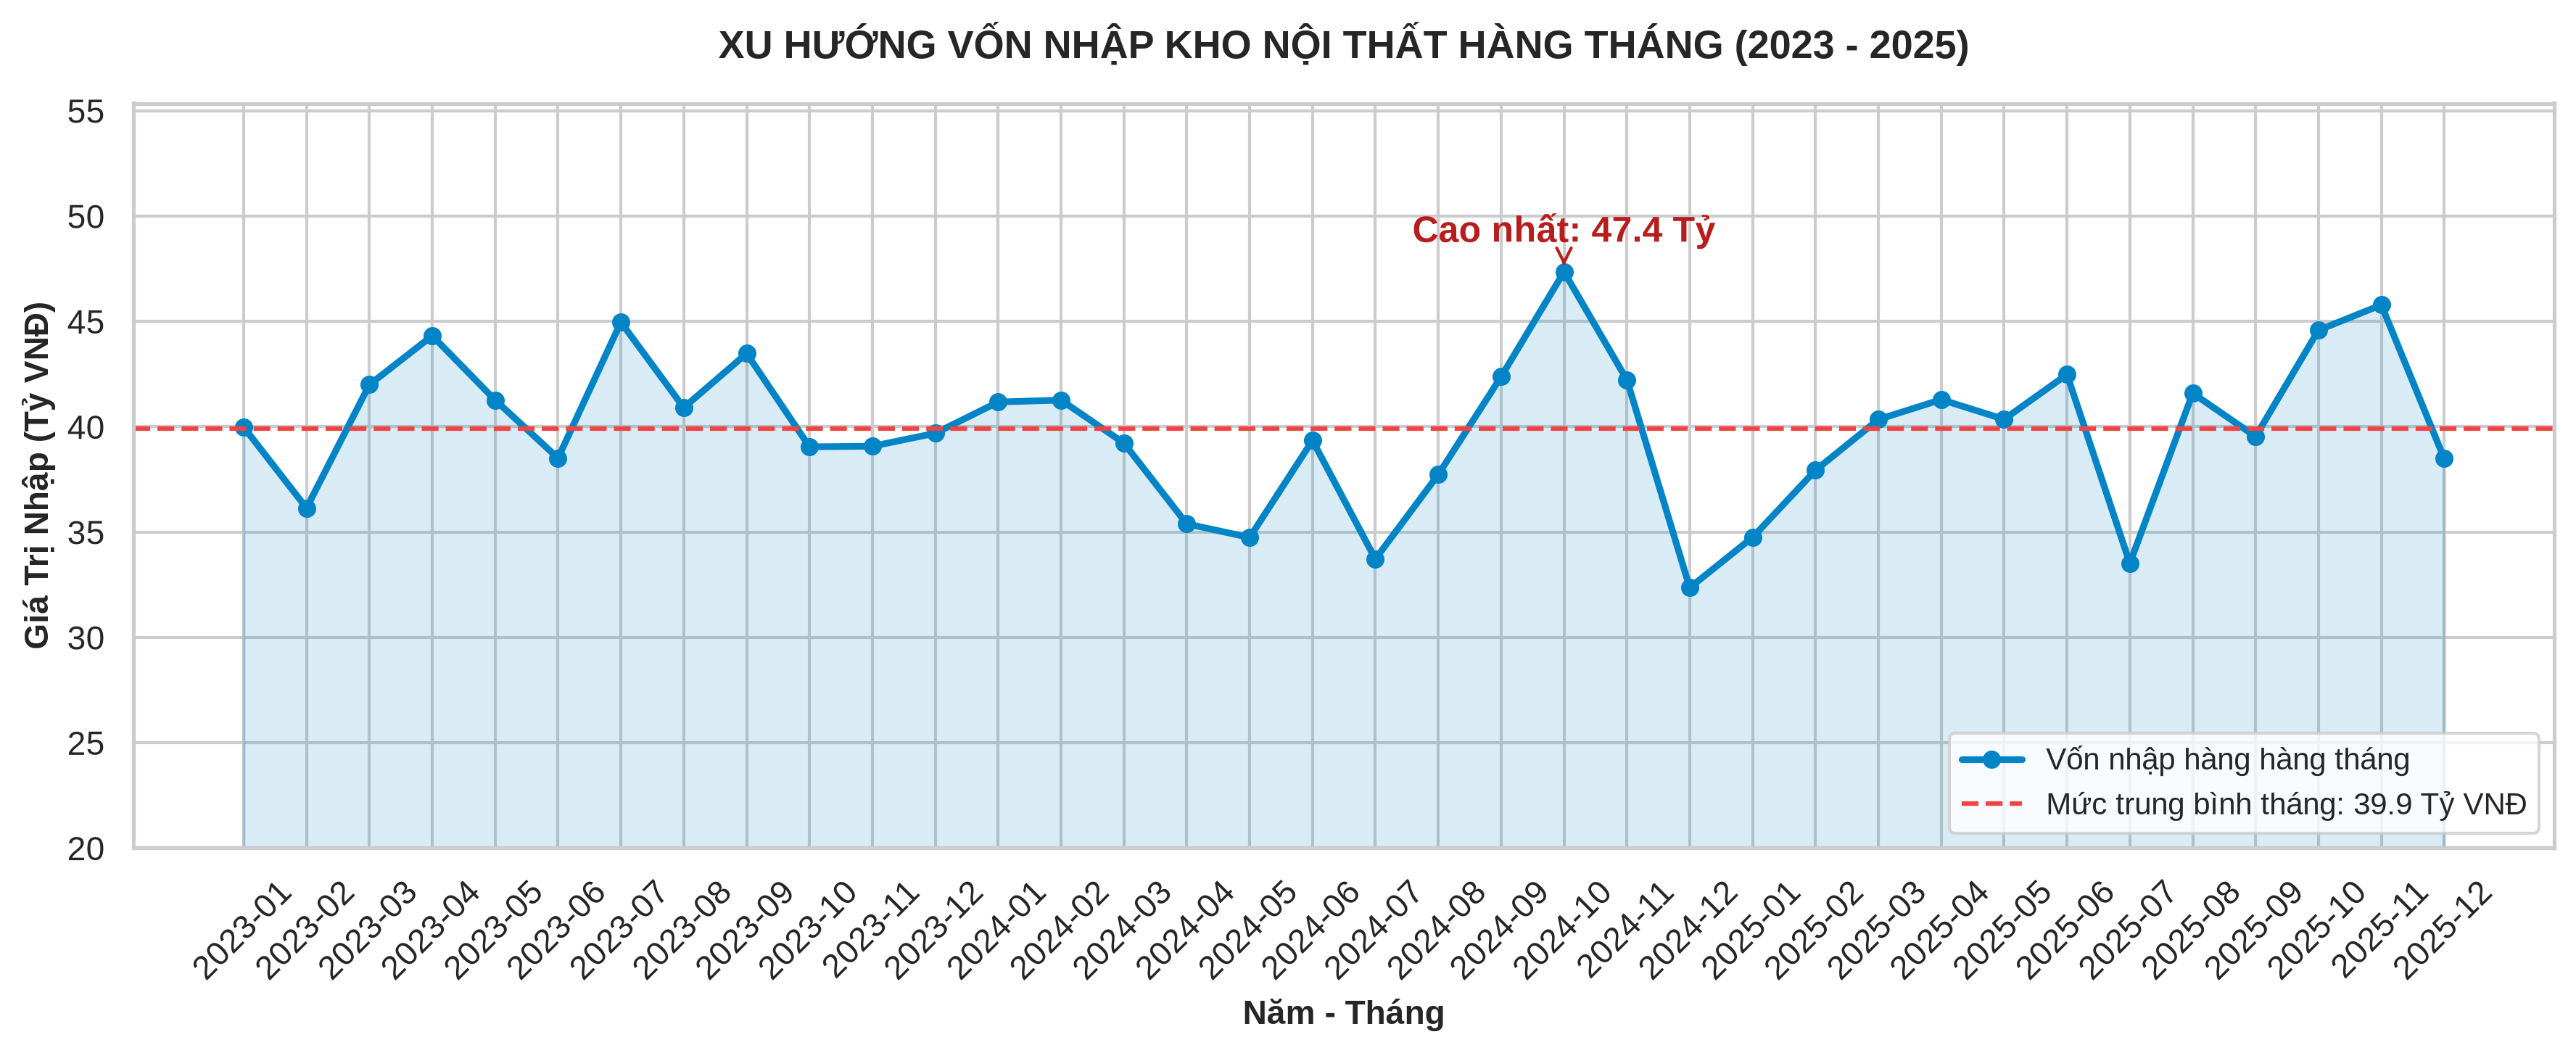

In [5]:
# Biểu đồ 3: Diễn biến giá trị nhập hàng theo tháng
monthly_trend = df.groupby('Năm_Tháng')['Thành Tiền (Tỷ VNĐ)'].sum().reset_index()
monthly_trend['Tháng_Str'] = monthly_trend['Năm_Tháng'].astype(str)
avg_monthly = monthly_trend['Thành Tiền (Tỷ VNĐ)'].mean()

fig, ax = plt.subplots(figsize=(12, 5), dpi=300)
ax.plot(monthly_trend['Tháng_Str'], monthly_trend['Thành Tiền (Tỷ VNĐ)'], 
        marker='o', markersize=5, color='#0284C7', linewidth=2.2, label='Vốn nhập hàng hàng tháng')
ax.fill_between(monthly_trend['Tháng_Str'], monthly_trend['Thành Tiền (Tỷ VNĐ)'], alpha=0.15, color='#0284C7')

# Đường trung bình
ax.axhline(avg_monthly, color='#EF4444', linestyle='--', linewidth=1.5, 
           label=f'Mức trung bình tháng: {avg_monthly:.1f} Tỷ VNĐ')

ax.set_title("XU HƯỚNG VỐN NHẬP KHO NỘI THẤT HÀNG THÁNG (2023 - 2025)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Năm - Tháng", fontsize=11, fontweight='bold')
ax.set_ylabel("Giá Trị Nhập (Tỷ VNĐ)", fontsize=11, fontweight='bold')
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(bottom=20, top=monthly_trend['Thành Tiền (Tỷ VNĐ)'].max() + 8)

# Đánh dấu đỉnh cao nhất và đáy thấp nhất
max_row = monthly_trend.loc[monthly_trend['Thành Tiền (Tỷ VNĐ)'].idxmax()]
min_row = monthly_trend.loc[monthly_trend['Thành Tiền (Tỷ VNĐ)'].idxmin()]
ax.annotate(f"Cao nhất: {max_row['Thành Tiền (Tỷ VNĐ)']:.1f} Tỷ", 
            xy=(max_row['Tháng_Str'], max_row['Thành Tiền (Tỷ VNĐ)']),
            xytext=(0, 10), textcoords="offset points", ha='center', fontweight='bold', color='#B91C1C',
            arrowprops=dict(arrowstyle='->', color='#B91C1C'))

ax.legend(frameon=True, loc='lower right', fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "03_xu_huong_theo_thang.png"), bbox_inches='tight')
plt.show()


---
### 📊 Biểu Đồ 4: Bảng Xếp Hạng Vốn Nhập Kho Theo Dòng Sản Phẩm
- **Dạng biểu đồ:** Biểu đồ cột ngang phân hạng (`sns.barplot` nằm ngang).
- **Mục đích:** Tên sản phẩm tiếng Việt đọc theo chiều ngang tự nhiên, dễ so sánh dòng hàng chiếm tỷ trọng vốn lớn nhất.


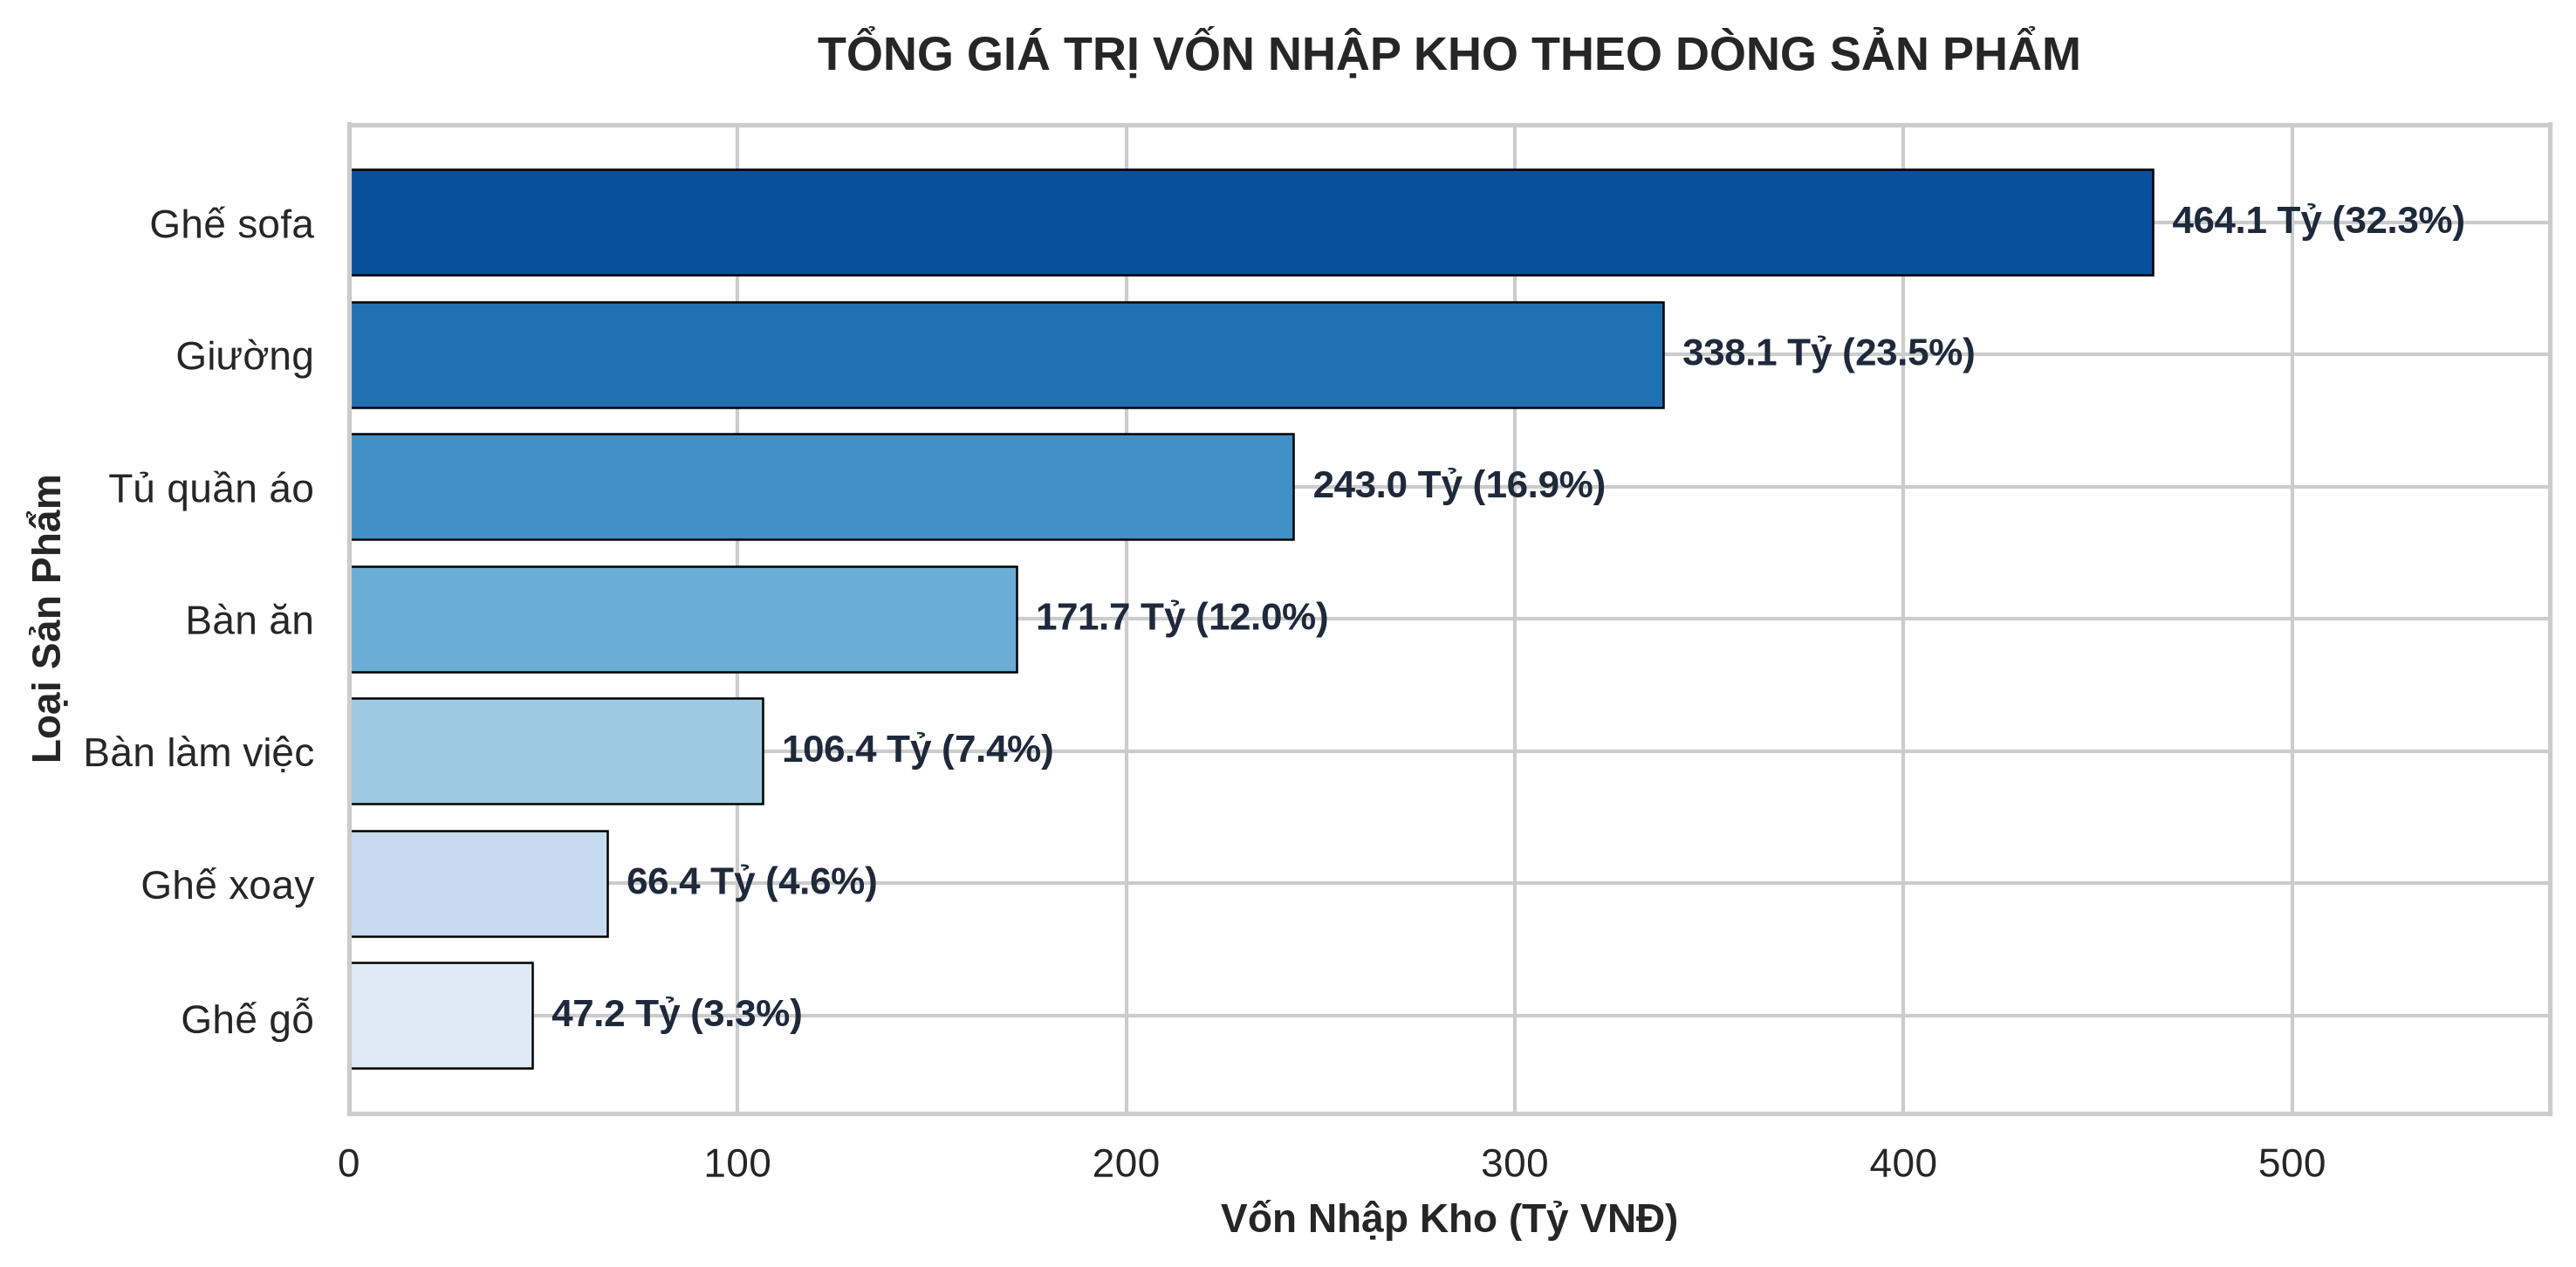

In [6]:
# Biểu đồ 4: Bảng xếp hạng vốn theo dòng sản phẩm
cat_ranking = df.groupby('Tên Sản Phẩm')['Thành Tiền (Tỷ VNĐ)'].sum().sort_values(ascending=True).reset_index()

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
palette = sns.color_palette("Blues", n_colors=len(cat_ranking))
bars = ax.barh(cat_ranking['Tên Sản Phẩm'], cat_ranking['Thành Tiền (Tỷ VNĐ)'], color=palette, edgecolor='black', linewidth=0.6)

# Ghi nhãn số liệu và % trực tiếp cạnh thanh bar
total_cat_val = cat_ranking['Thành Tiền (Tỷ VNĐ)'].sum()
for bar in bars:
    w = bar.get_width()
    pct = (w / total_cat_val) * 100
    ax.text(w + 5, bar.get_y() + bar.get_height()/2, f"{w:,.1f} Tỷ ({pct:.1f}%)", 
            va='center', ha='left', fontsize=10.5, fontweight='bold', color='#1E293B')

ax.set_xlim(0, cat_ranking['Thành Tiền (Tỷ VNĐ)'].max() * 1.22)
ax.set_title("TỔNG GIÁ TRỊ VỐN NHẬP KHO THEO DÒNG SẢN PHẨM", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Vốn Nhập Kho (Tỷ VNĐ)", fontsize=11, fontweight='bold')
ax.set_ylabel("Loại Sản Phẩm", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "04_xep_hang_san_pham.png"), bbox_inches='tight')
plt.show()


---
### 📊 Biểu Đồ 5: So Sánh Vốn Nhập Kho Nội Địa vs Nhập Khẩu Trên Từng Mặt Hàng
- **Dạng biểu đồ:** Biểu đồ cột nhóm (`sns.barplot` grouped).
- **Mục đích:** Thấy rõ mặt hàng nào phụ thuộc nhiều vào hàng nhập khẩu, mặt hàng nào chủ đạo là nội địa.


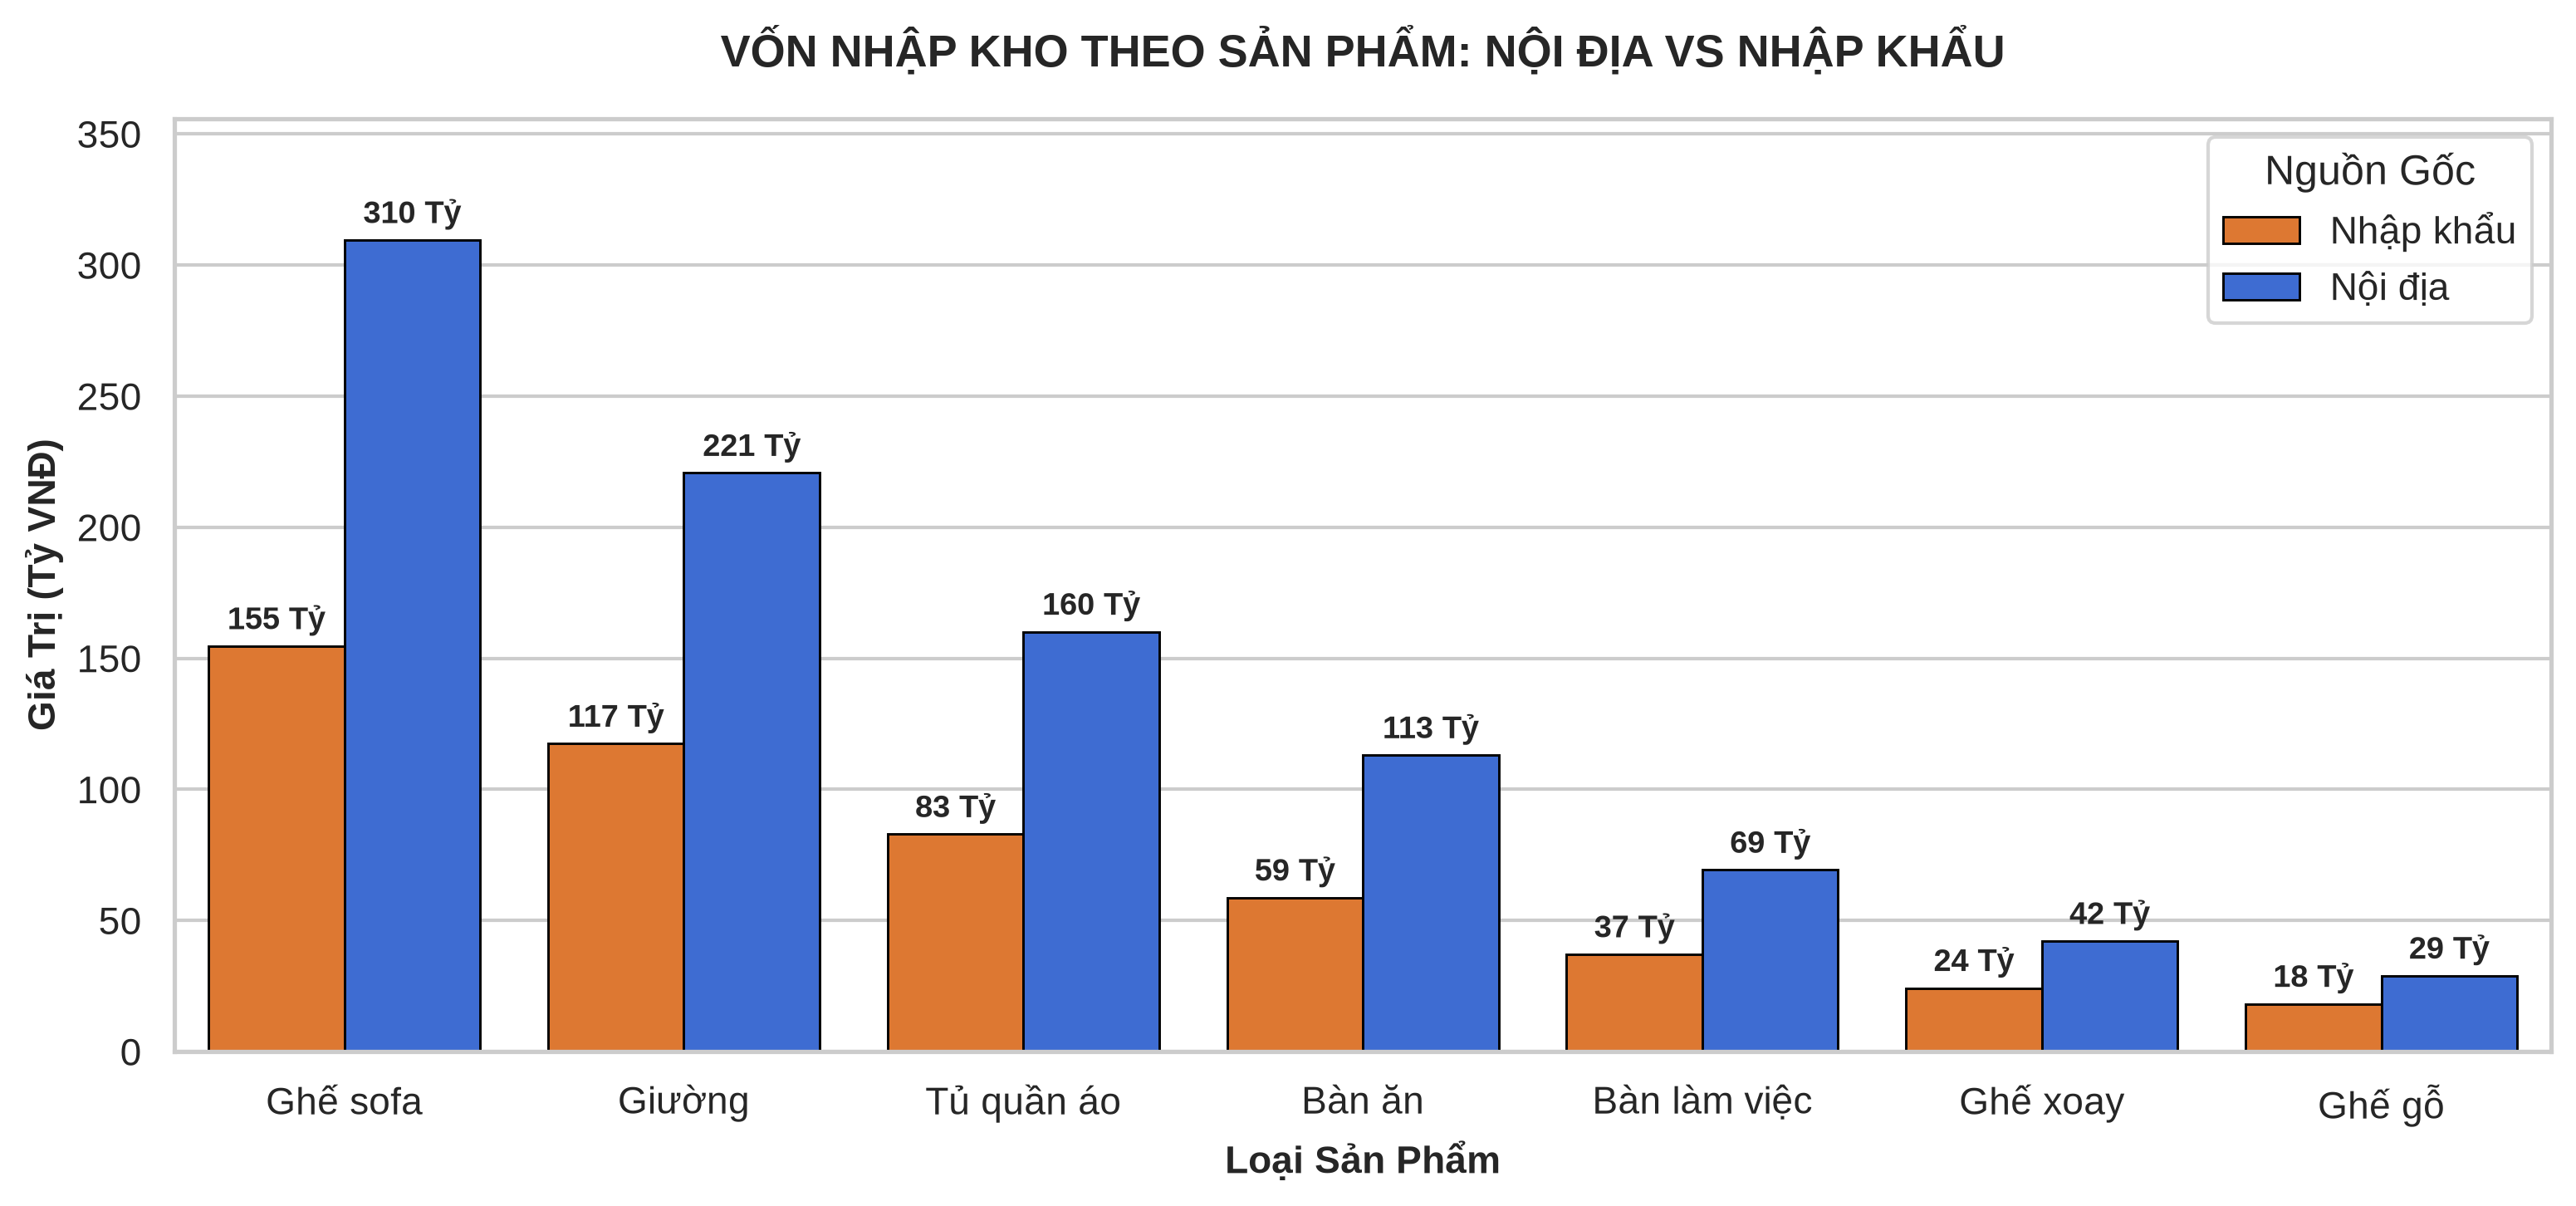

In [7]:
# Biểu đồ 5: So sánh Nguồn Gốc trên từng Mặt Hàng
cat_origin = df.groupby(['Tên Sản Phẩm', 'Nguồn Gốc'])['Thành Tiền (Tỷ VNĐ)'].sum().reset_index()
order_cat = df.groupby('Tên Sản Phẩm')['Thành Tiền (Tỷ VNĐ)'].sum().sort_values(ascending=False).index.tolist()

fig, ax = plt.subplots(figsize=(10.5, 5), dpi=300)
sns.barplot(
    data=cat_origin, 
    x='Tên Sản Phẩm', 
    y='Thành Tiền (Tỷ VNĐ)', 
    hue='Nguồn Gốc', 
    order=order_cat,
    palette={'Nội địa': '#2563EB', 'Nhập khẩu': '#F97316'},
    edgecolor='black',
    linewidth=0.7,
    ax=ax
)

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:,.0f} Tỷ", 
                    (p.get_x() + p.get_width() / 2., h), 
                    ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3), 
                    textcoords='offset points')

ax.set_ylim(0, cat_origin['Thành Tiền (Tỷ VNĐ)'].max() * 1.15)
ax.set_title("VỐN NHẬP KHO THEO SẢN PHẨM: NỘI ĐỊA VS NHẬP KHẨU", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Loại Sản Phẩm", fontsize=11, fontweight='bold')
ax.set_ylabel("Giá Trị (Tỷ VNĐ)", fontsize=11, fontweight='bold')
ax.legend(title="Nguồn Gốc", frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "05_nguon_goc_theo_san_pham.png"), bbox_inches='tight')
plt.show()


---
### 📊 Biểu Đồ 6: Đánh Giá Rủi Ro Chất Lượng Từng Mặt Hàng (100% Stacked Bar)
- **Dạng biểu đồ:** Biểu đồ cột chồng 100% chuẩn hóa.
- **Mục đích:** Giúp bộ phận Quản lý chất lượng (QA/QC) và Thu mua nhận diện ngay mặt hàng nào có rủi ro hư hỏng/sửa chữa cao bất thường.


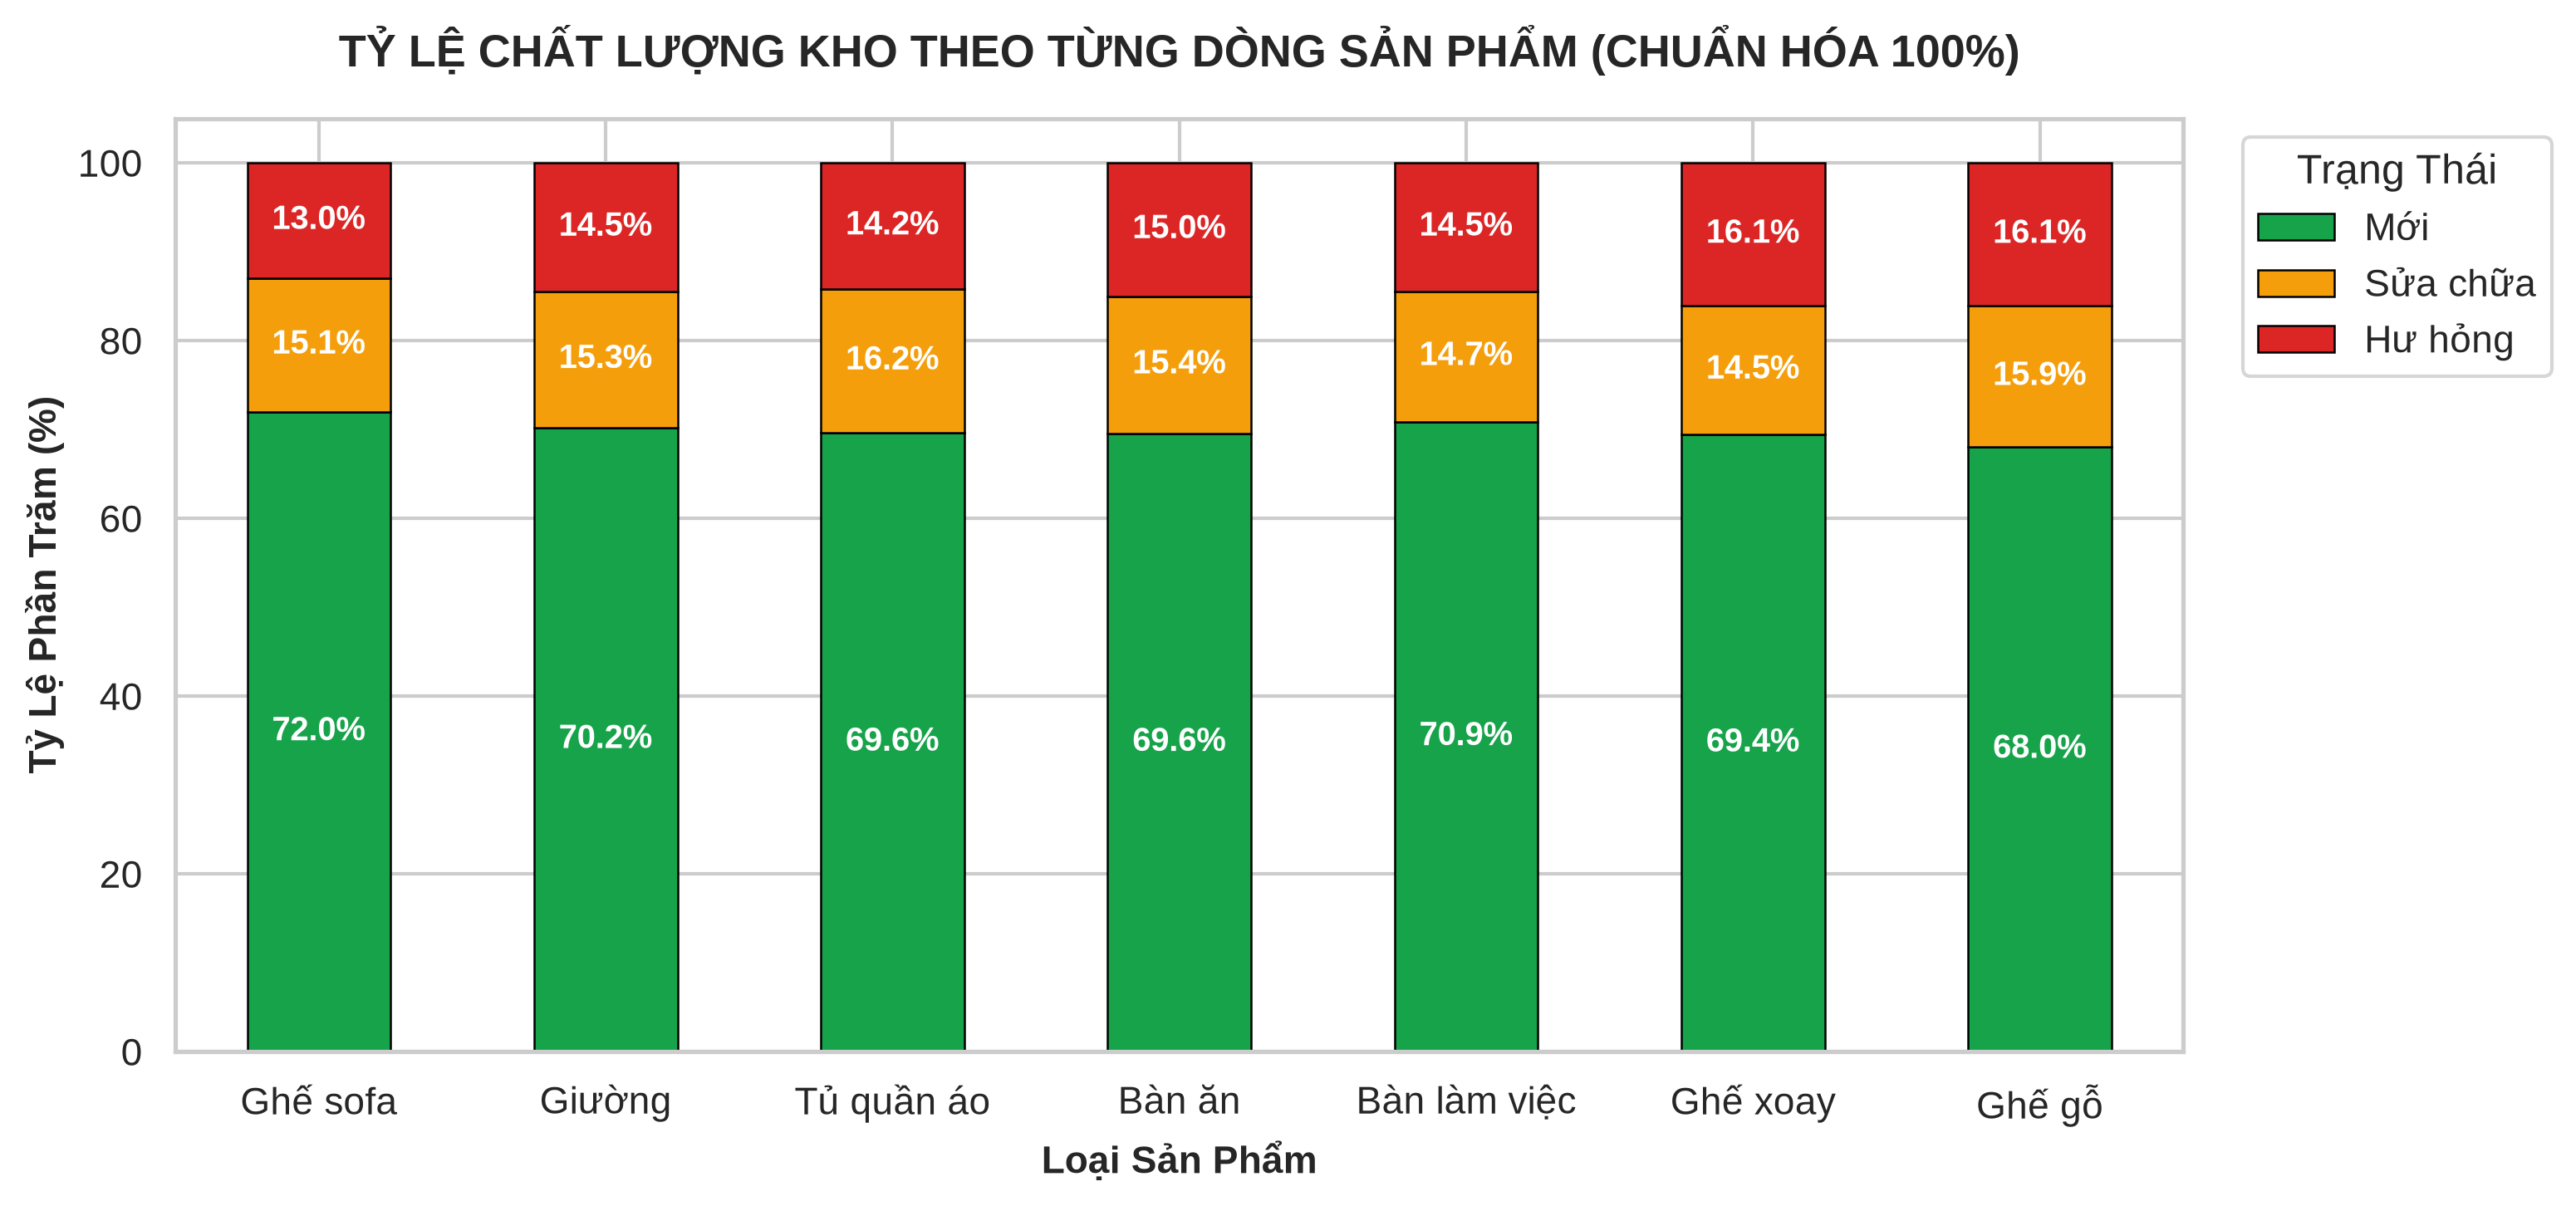

In [8]:
# Biểu đồ 6: Tỷ lệ chất lượng chuẩn hóa 100%
quality_ct = pd.crosstab(df['Tên Sản Phẩm'], df['Trạng Thái'], normalize='index')[['Mới', 'Sửa chữa', 'Hư hỏng']] * 100
quality_ct = quality_ct.loc[order_cat] # Sắp xếp theo thứ tự quy mô vốn

fig, ax = plt.subplots(figsize=(10.5, 5), dpi=300)
colors_stack = ['#16A34A', '#F59E0B', '#DC2626'] # Xanh lá, Cam, Đỏ
quality_ct.plot(kind='bar', stacked=True, ax=ax, color=colors_stack, edgecolor='black', linewidth=0.6)

# Hiển thị số % vào tâm từng đoạn cột
for n, c in enumerate(quality_ct.columns):
    for i, val in enumerate(quality_ct[c]):
        cum_val = quality_ct.iloc[i, :n].sum() + val/2
        ax.text(i, cum_val, f"{val:.1f}%", ha='center', va='center', 
                color='white', fontweight='bold', fontsize=9.5)

ax.set_title("TỶ LỆ CHẤT LƯỢNG KHO THEO TỪNG DÒNG SẢN PHẨM (CHUẨN HÓA 100%)", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Loại Sản Phẩm", fontsize=11, fontweight='bold')
ax.set_ylabel("Tỷ Lệ Phần Trăm (%)", fontsize=11, fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.set_ylim(0, 105)
ax.legend(title="Trạng Thái", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "06_ty_le_chat_luong_chi_tiet.png"), bbox_inches='tight')
plt.show()


---
### 📊 Biểu Đồ 7: Phân Bố Mức Đơn Giá Nhập Kho Theo Dòng Sản Phẩm
- **Dạng biểu đồ:** Biểu đồ hộp (`sns.boxplot`).
- **Mục đích:** Thể hiện dải giá dao động (từ tối thiểu, trung vị, đến mức giá cao nhất) và phát hiện các lô hàng có giá trị đột biến.


/tmp/ipykernel_1655457/2235456415.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


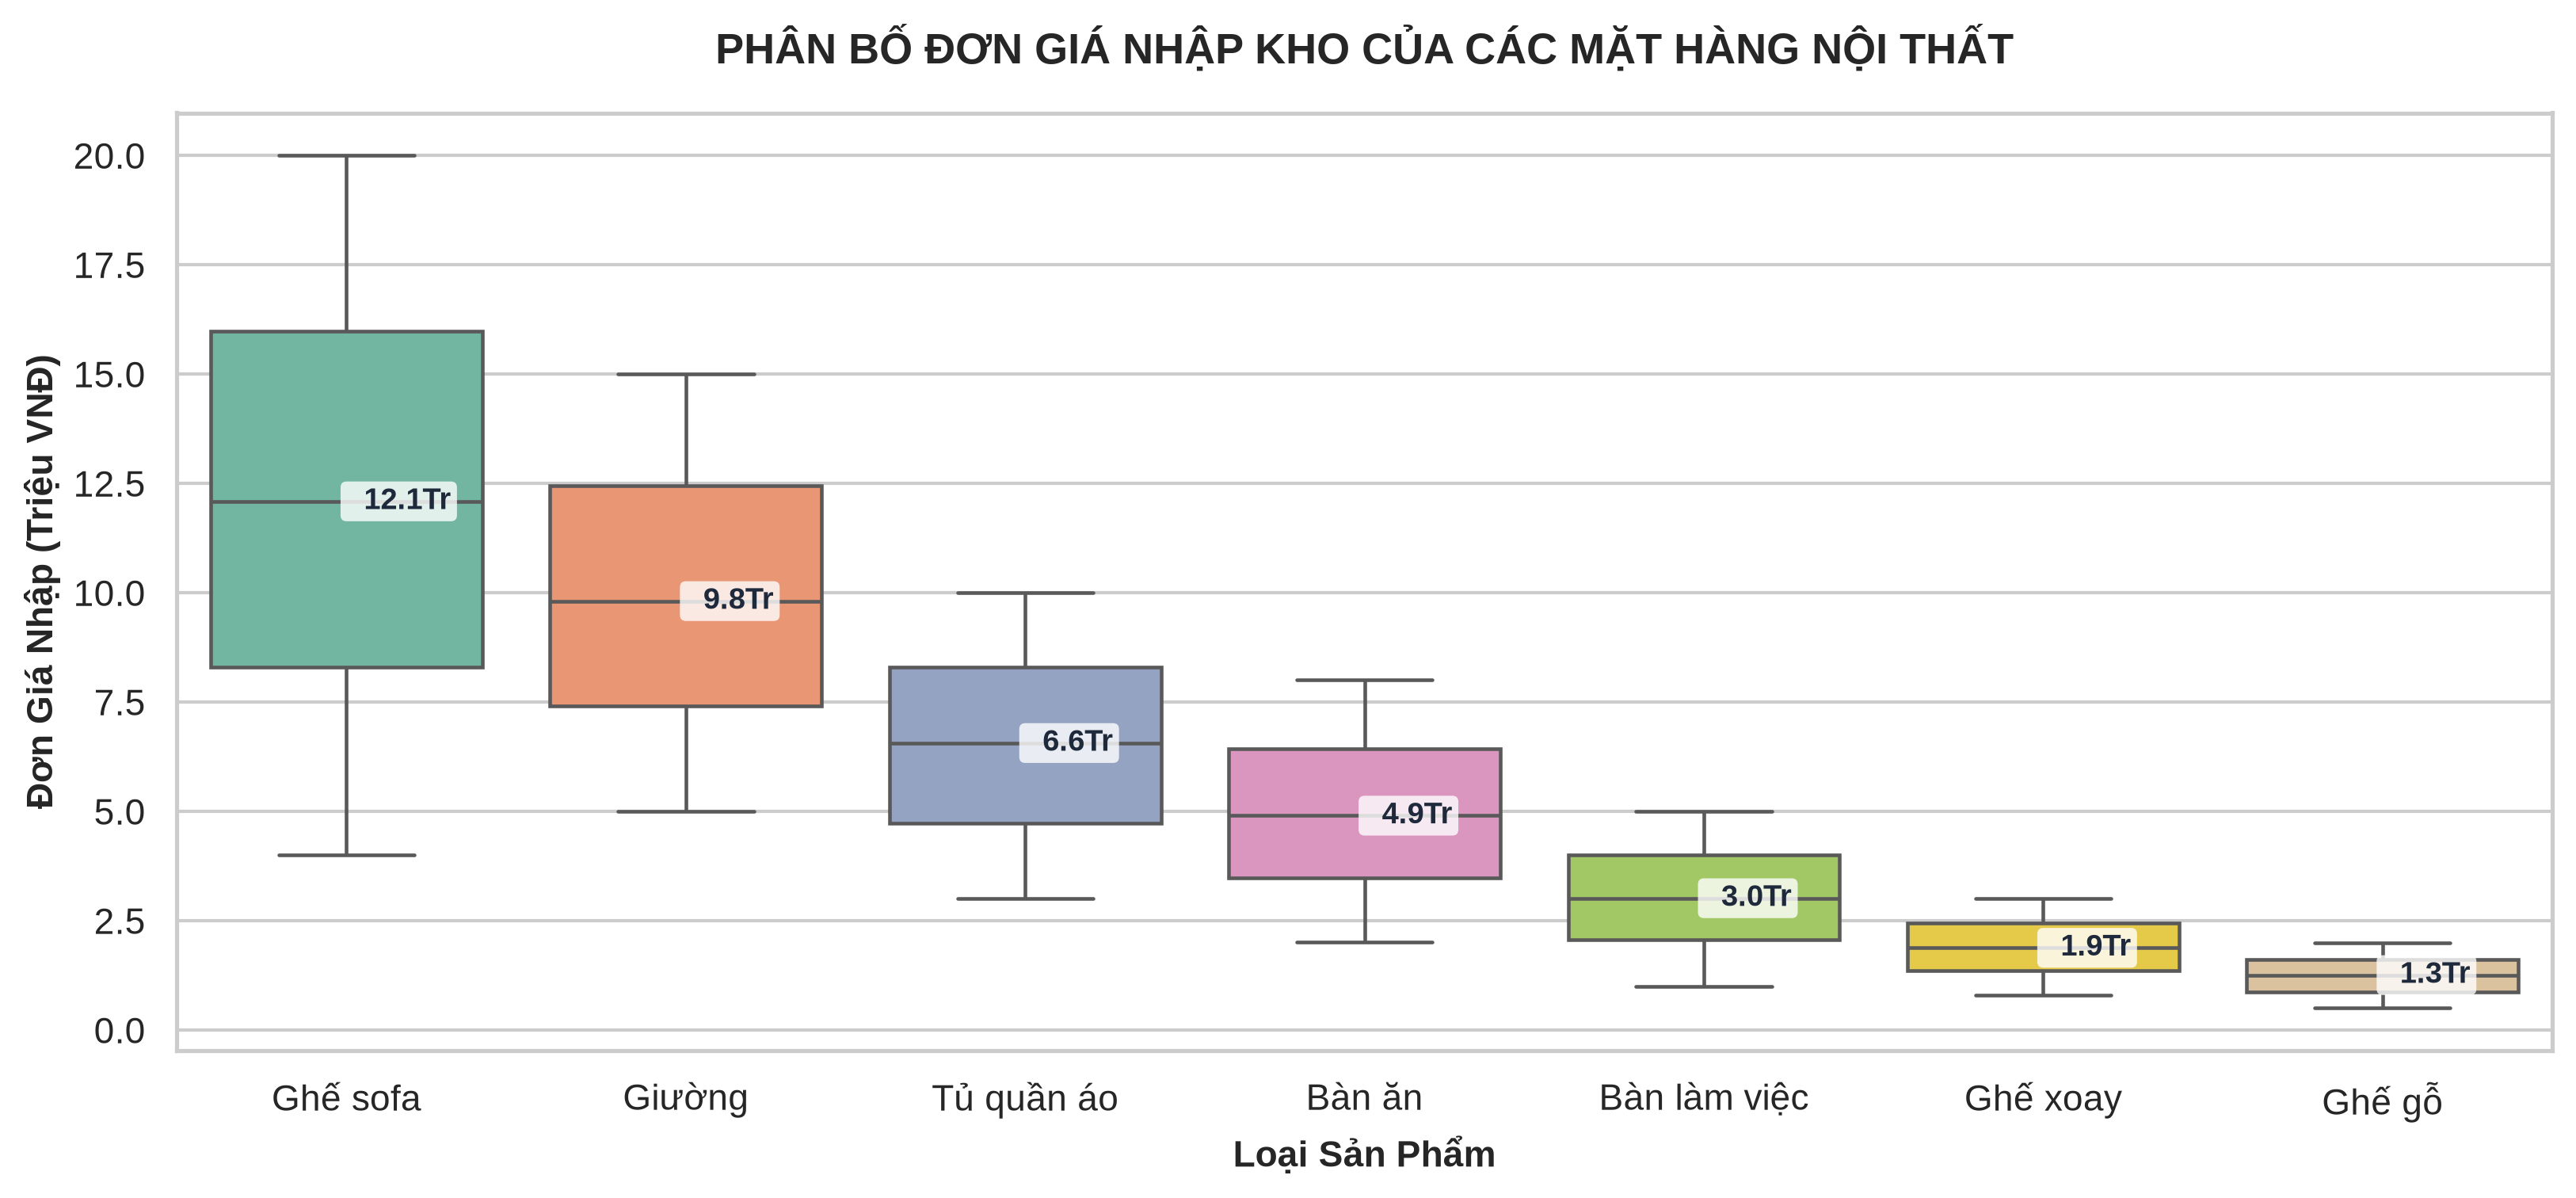

In [9]:
# Biểu đồ 7: Phân bố mức giá nhập kho của từng sản phẩm
fig, ax = plt.subplots(figsize=(11, 5.2), dpi=300)
sns.boxplot(
    data=df, 
    x='Tên Sản Phẩm', 
    y='Giá Nhập (Triệu VNĐ)', 
    order=order_cat,
    palette="Set2",
    ax=ax,
    fliersize=2,
    linewidth=1.1
)

# Thêm giá trị trung vị bằng số lên đầu từng hộp
medians = df.groupby('Tên Sản Phẩm')['Giá Nhập (Triệu VNĐ)'].median().loc[order_cat]
for i, med in enumerate(medians):
    ax.text(i, med, f"  {med:.1f}Tr", ha='left', va='center', fontsize=9, fontweight='bold', color='#1E293B',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8, edgecolor='none'))

ax.set_title("PHÂN BỐ ĐƠN GIÁ NHẬP KHO CỦA CÁC MẶT HÀNG NỘI THẤT", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Loại Sản Phẩm", fontsize=11, fontweight='bold')
ax.set_ylabel("Đơn Giá Nhập (Triệu VNĐ)", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(IMG_DIR, "07_phan_bo_don_gia.png"), bbox_inches='tight')
plt.show()


---
## 🎯 Bảng Đúc Kết Nhận Định & Khuyến Nghị Vận Hành

| Cấp độ phân tích | Phát hiện chính | Ý nghĩa thực tiễn / Khuyến nghị |
| :--- | :--- | :--- |
| **Tổng quan vĩ mô** | Tổng vốn nhập đạt **1.437 Tỷ VNĐ**, trong đó **65.7%** giá trị đến từ nguồn nội địa. | Nguồn cung nội địa là xương sống ổn định; cần duy trì hợp đồng chiến lược với đối tác trong nước. |
| **Xu hướng thời gian** | Vốn nhập phân bổ đều đặn ~40 Tỷ/tháng qua 3 năm (2023 - 2025). | Không có hiện tượng biến động gãy đổ dòng tiền, tiến độ cung ứng duy trì rất nhịp nhàng. |
| **Danh mục chủ lực** | **Ghế sofa** (464 Tỷ) & **Giường** (338 Tỷ) chiếm hơn **55%** tổng vốn lưu chuyển. | Ưu tiên tối ưu không gian bảo quản và chu kỳ quay vòng kho cho 2 nhóm mặt hàng giá trị cao này. |
| **Rủi ro chất lượng** | Tỷ lệ hàng đạt chuẩn (Mới) đạt **~70%**; hàng cần sửa chữa hoặc hư hỏng chiếm **~30%** ở cả 7 dòng hàng. | Tỷ lệ lỗi 30% là tương đối lớn; cần rà soát lại quy trình đóng gói, bốc xếp vận chuyển và kiểm định từ xưởng sản xuất. |
